# Graphiques de performance — mandat 3 (suivi de particules)

Ce notebook produit les **graphiques de performance 1 à 5** de l'annexe 2 et la **figure d'annexe sur les pertes
d'images**, uniquement à partir des **6 vidéos réelles du test** (vidéos 2 à 7 du rapport du test, billes de
référence a = 0,475 ± 0,010 µm). **Aucune simulation.**

Pour chaque paramètre, deux métriques (axe y gauche et axe y droit, comme au mandat 2) :

* **Exactitude** : $E_a = \bar a - a_\mathrm{vrai}$, où $\bar a$ est la moyenne des rayons des 6 vidéos
  (le rayon d'une vidéo vient de la moyenne des $D_i$ de ses billes, comme dans `rayon_final`).
  Barre d'erreur : écart type des 6 rayons de vidéo / √6.
* **Précision absolue** : $u_a = \sqrt{\sum_v u_v^2}\,/\,6$ avec $u_v = \mathrm{std}(a_i)/\sqrt{N_v}$
  (écart type des rayons des $N_v$ billes de la vidéo $v$). Barre d'erreur : rééchantillonnage (bootstrap) des billes.

Paramètres variés : 1) nombre de décalages L du MSD, 2) fréquence d'image (exposition fixée à 90 ms),
3) profondeur de bits, 4) taille de pixel, 5) quantité de données (nombre d'images, nombre de billes).

**Point de départ** : le résultat final du test (code `traitement_video_tiff_extra.py`, L = 4, vibration retirée
avec les billes immobiles de référence, regroupements et exclusions manuels), exporté dans
`donnees/test_6videos_final.pkl`. Ce fichier contient, pour chaque vidéo, les pistes des billes gardées (positions
brutes et positions corrigées de la vibration) et les pistes de référence. Les choix manuels ne sont donc pas refaits.

**Pour relancer** : `Run All`. Les graphiques 3 et 4 relisent les TIFF de
`../techex_M3_videos/_avant_premier_trou/` et relocalisent chaque bille dans chaque image dégradée
(≈ 10 à 20 min la première fois); le résultat est mis en cache dans `donnees/cache_relocalisation/`.
Effacer ce dossier pour tout recalculer. Les figures sont écrites dans `fig_performance/`.

In [1]:
import sys, json, glob, pickle, time
from pathlib import Path
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

ICI = Path.cwd()                                   # dossier performance/
RACINE = ICI.parent                                # dossier M3_Microscope/
sys.path.insert(0, str(RACINE))
import traitement_video_tiff_extra as M            # seulement des fonctions de calcul : rien n'est modifié

DONNEES = ICI / "donnees" / "test_6videos_final.pkl"
DOSSIER_VIDEOS = RACINE / "techex_M3_videos" / "_avant_premier_trou"
DOSSIER_JSON = RACINE / "techex_M3_videos"
CACHE = ICI / "donnees" / "cache_relocalisation"
FIG = ICI / "fig_performance"
FIG.mkdir(exist_ok=True); CACHE.mkdir(parents=True, exist_ok=True)

A_VRAI_UM, INC_VRAI_UM = 0.475, 0.010     # billes de référence : diamètre 0,95 ± 0,02 µm
L_PROTO = 4                               # nombre de décalages du protocole du test
N_MIN_PTS = 10                            # positions minimales pour ajuster un MSD après dégradation
N_BOOT = 1000
GRAINE = 0

donnees = pickle.load(open(DONNEES, "rb"))
VIDEOS = list(donnees)
for v, d in donnees.items():
    print(f"{v} ({d['fichier_code']}) : {len(d['billes'])} billes gardées, {len(d['refs'])} pistes de référence, "
          f"{d['n_creneaux']} images, Δt = {d['dt']*1e3:.1f} ms, pixel {d['pixel_eff']*1e6:.3f} µm, "
          f"a officiel = {d['a_officiel']*1e6:.3f} ± {d['inc_officiel']*1e6:.3f} µm")

Vidéo 2 (p1) : 9 billes gardées, 6 pistes de référence, 149 images, Δt = 92.0 ms, pixel 0.374 µm, a officiel = 0.630 ± 0.093 µm
Vidéo 3 (p3) : 12 billes gardées, 7 pistes de référence, 111 images, Δt = 92.0 ms, pixel 0.374 µm, a officiel = 0.436 ± 0.057 µm
Vidéo 4 (p4) : 10 billes gardées, 3 pistes de référence, 166 images, Δt = 92.0 ms, pixel 0.374 µm, a officiel = 0.527 ± 0.040 µm
Vidéo 5 (p5) : 10 billes gardées, 11 pistes de référence, 143 images, Δt = 92.0 ms, pixel 0.374 µm, a officiel = 0.464 ± 0.031 µm
Vidéo 6 (p6) : 18 billes gardées, 5 pistes de référence, 184 images, Δt = 92.0 ms, pixel 0.374 µm, a officiel = 0.466 ± 0.028 µm
Vidéo 7 (p7) : 15 billes gardées, 16 pistes de référence, 135 images, Δt = 92.0 ms, pixel 0.374 µm, a officiel = 0.472 ± 0.035 µm


## Métriques communes

In [2]:
def rayon_um(D):
    """Stokes-Einstein, a = kT/(6πηD), en µm (T = 295,15 K, η = 0,95 mPa·s, comme le code du prototype)."""
    return M.kB * M.T / (6 * np.pi * M.ETA * np.asarray(D, float)) * 1e6


def u_video(D):
    """u_v = std(a_i)/√N_v, évalué par propagation à partir des D_i. Le rayon d'une vidéo vient de la moyenne des D_i
    (rayon_final), donc u_v = a_v · [std(D_i)/√N_v] / moyenne(D_i). L'écart type direct des rayons a_i = kT/(6πηD_i)
    est inutilisable : une seule bille à D presque nul a un rayon qui tend vers l'infini et domine l'écart type."""
    return rayon_um(D.mean()) * np.std(D, ddof=1) / np.sqrt(len(D)) / D.mean()


def metriques(D_videos, n_boot=N_BOOT, graine=GRAINE):
    """D_videos : liste (une entrée par vidéo) des D_i (m²/s) des billes. Retourne E_a, u_a (µm) et leurs barres.
    E_a = moyenne des 6 rayons de vidéo − a_vrai, barre = écart type des rayons de vidéo / √6.
    u_a = √(Σ u_v²) / 6, barre = demi-largeur 16-84 % du bootstrap des billes (robuste aux tirages à D presque nul)."""
    D_videos = [np.asarray([x for x in D if np.isfinite(x)]) for D in D_videos]
    ok = [len(D) >= 2 and D.mean() > 0 for D in D_videos]
    Dm = np.array([D.mean() if o else np.nan for D, o in zip(D_videos, ok)])      # D moyen de chaque vidéo
    D_ok = [D for D, o in zip(D_videos, ok) if o]
    if len(D_ok) < 2:
        return dict(E=np.nan, sE=np.nan, u=np.nan, su=np.nan, a_v=[], N=[], n_vid=len(D_ok), D_moy=Dm, u_v=[])
    a_v = rayon_um(Dm[np.isfinite(Dm)])
    n = len(a_v)
    E, sE = a_v.mean() - A_VRAI_UM, a_v.std(ddof=1) / np.sqrt(n)
    u_v = np.array([u_video(D) for D in D_ok])
    u = np.sqrt(np.sum(u_v**2)) / n
    rng = np.random.default_rng(graine)
    boots = []
    for _ in range(n_boot):
        tir = [rng.choice(D, len(D)) for D in D_ok]
        boots.append(np.sqrt(sum(u_video(t)**2 if t.mean() > 0 else np.inf for t in tir)) / n)
    su = float(np.diff(np.percentile(boots, [16, 84]))[0] / 2)
    u_brut = np.sqrt(sum(np.std(rayon_um(D), ddof=1)**2 / len(D) for D in D_ok)) / n   # définition directe, comparaison
    return dict(E=E, sE=sE, u=u, su=su, a_v=a_v, N=[len(D) for D in D_ok], n_vid=n, D_moy=Dm, u_v=u_v, u_brut=u_brut)


def combiner(liste):
    """Moyenne de plusieurs analyses du même réglage (phases de décimation, fenêtres d'images).
    Exactitude : D moyen de chaque vidéo moyenné sur les analyses, puis rayon (l'erreur systématique, sans le bruit).
    Précision : médiane des u_a des analyses (chacune représente UNE acquisition réelle à ce réglage)."""
    liste = [r for r in liste if np.isfinite(r["u"])]
    Dm = np.nanmean([r["D_moy"] for r in liste], axis=0)
    a_v = rayon_um(Dm[np.isfinite(Dm) & (Dm > 0)])
    return dict(E=a_v.mean() - A_VRAI_UM, sE=a_v.std(ddof=1) / np.sqrt(len(a_v)), a_v=a_v,
                u=float(np.median([r["u"] for r in liste])), su=float(np.median([r["su"] for r in liste])),
                N=float(np.mean([sum(r["N"]) for r in liste])), n_analyses=len(liste))


def D_piste(pos_px, dt, pe, L=L_PROTO, n_min=N_MIN_PTS):
    """D (m²/s) par la régression du MSD sur L décalages (même fonction que le prototype)."""
    if np.isfinite(pos_px[:, 0]).sum() < max(n_min, L + 1):
        return np.nan
    return M.ajuste_msd(pos_px * pe, dt, L)[0]


# Vérification : les positions exportées redonnent exactement le résultat officiel du test (L = 4)
base = metriques([[D_piste(b["pos_msd"], d["dt"], d["pixel_eff"]) for b in d["billes"]] for d in donnees.values()])
for v, d, a in zip(VIDEOS, donnees.values(), base["a_v"]):
    print(f"{v} : a = {a:.3f} µm (officiel {d['a_officiel']*1e6:.3f})")
print(f"Moyenne des 6 vidéos : {base['E'] + A_VRAI_UM:.3f} µm  ->  E_a = {base['E']*1e3:+.0f} ± {base['sE']*1e3:.0f} nm,"
      f"  u_a = {base['u']*1e3:.0f} ± {base['su']*1e3:.0f} nm (écart type direct des a_i : {base['u_brut']*1e3:.0f} nm),"
      f"  billes : {base['N']}")

Vidéo 2 : a = 0.630 µm (officiel 0.630)
Vidéo 3 : a = 0.436 µm (officiel 0.436)
Vidéo 4 : a = 0.527 µm (officiel 0.527)
Vidéo 5 : a = 0.464 µm (officiel 0.464)
Vidéo 6 : a = 0.466 µm (officiel 0.466)
Vidéo 7 : a = 0.472 µm (officiel 0.472)
Moyenne des 6 vidéos : 0.499 µm  ->  E_a = +24 ± 29 nm,  u_a = 29 ± 7 nm (écart type direct des a_i : 85 nm),  billes : [9, 12, 10, 10, 18, 15]


## Style des figures (celui du mandat 2 : deux axes y, cercles bleus et carrés orange)

In [3]:
BLEU, ORANGE, GRIS, TXT = "#2a78d6", "#d9622b", "#8a8986", "#0b0b0b"
mpl.rcParams.update({
    "font.family": "STIXGeneral", "mathtext.fontset": "stix", "font.size": 10.5,
    "axes.linewidth": 0.8, "axes.edgecolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "xtick.direction": "out", "ytick.direction": "out", "savefig.dpi": 220, "figure.dpi": 110,
    "axes.spines.top": False,
})


def panneau(ax, x, res, xlabel, lettre=None, proto=None, log=False, xticks=None, xticklabels=None,
            note_proto="prototype", ylim_E=None, ylim_u=None):
    """Un graphique à deux axes y : exactitude E_a (gauche, cercles bleus) et précision u_a (droite, carrés orange)."""
    x = np.asarray(x, float)
    E = np.array([r["E"] for r in res]) * 1e3; sE = np.array([r["sE"] for r in res]) * 1e3
    u = np.array([r["u"] for r in res]) * 1e3; su = np.array([r["su"] for r in res]) * 1e3
    ax.axhspan(-INC_VRAI_UM * 1e3, INC_VRAI_UM * 1e3, color="#e9e8e4", zorder=0, lw=0)
    ax.axhline(0, color=GRIS, lw=0.8, ls="--", zorder=1)
    if proto is not None:
        ax.axvline(proto, color=GRIS, lw=0.8, ls=":", zorder=1)
    ax.errorbar(x, E, yerr=sE, color=BLEU, marker="o", ms=5, lw=1, alpha=0.95, capsize=2.5, elinewidth=0.9,
                zorder=3)
    ax.set_xlabel(xlabel, style="italic")
    ax.set_ylabel(r"Exactitude $E_a$ (nm)", color=BLEU, style="italic")
    ax.tick_params(axis="y", colors=BLEU)
    ax.spines["left"].set_color(BLEU)
    ax2 = ax.twinx()
    ax2.spines["top"].set_visible(False)
    ax2.errorbar(x, u, yerr=su, color=ORANGE, marker="s", ms=4.6, lw=1, alpha=0.95, capsize=2.5, elinewidth=0.9,
                 zorder=3)
    ax2.set_ylabel(r"Précision $u_a$ (nm)", color=ORANGE, style="italic")
    ax2.tick_params(axis="y", colors=ORANGE)
    ax2.spines["right"].set_color(ORANGE); ax2.spines["left"].set_visible(False)
    if log:
        ax.set_xscale("log")
    if xticks is not None:
        ax.set_xticks(xticks)
        if xticklabels is not None:
            ax.set_xticklabels(xticklabels)
        ax.minorticks_off() if log else None
    if ylim_E is not None:
        ax.set_ylim(*ylim_E)
    hi = np.nanmax(u + np.minimum(su, u))          # une barre plus grande que la valeur elle-même dépasse l'axe
    ax2.set_ylim(*(ylim_u if ylim_u is not None else (0, hi * 1.12)))
    if ylim_E is None:
        hiE = np.nanmax(E + np.minimum(sE, np.abs(E) + 60)); loE = np.nanmin(E - np.minimum(sE, np.abs(E) + 60))
        pad = 0.08 * (hiE - loE)
        ax.set_ylim(min(loE, -INC_VRAI_UM * 1e3) - pad, max(hiE, INC_VRAI_UM * 1e3) + pad)
    if lettre:
        ax.text(-0.02, 1.035, lettre, transform=ax.transAxes, fontsize=13, fontweight="bold", va="bottom", ha="right")
    if proto is not None and note_proto:
        ax.annotate(note_proto, xy=(proto, 1), xycoords=("data", "axes fraction"), xytext=(3, -3),
                    textcoords="offset points", fontsize=8.5, color="#52514e", va="top")
    return ax2


def enregistrer(fig, nom):
    fig.savefig(FIG / f"{nom}.png", bbox_inches="tight", facecolor="white")
    fig.savefig(FIG / f"{nom}.pdf", bbox_inches="tight", facecolor="white")


RESULTATS = {}          # tout ce qui est tracé, exporté en JSON à la fin

## Graphique 1 — Nombre de décalages L

On refait la régression du MSD de chaque bille gardée avec L = 1 à 12 décalages, sur les mêmes positions
(corrigées de la vibration). Avec L = 1, la droite est forcée par l'origine (D = MSD(Δt)/(4Δt)) : l'erreur de
localisation et le flou de mouvement ne sont pas séparés de la diffusion.

L =  1 : E_a =    -53 ±  55 nm   u_a =   22 ±   3 nm  (direct     24 nm)   rayons par vidéo [0.441 0.643 0.403 0.479 0.294 0.273]
L =  2 : E_a =   +122 ±  70 nm   u_a =   66 ±  62 nm  (direct    168 nm)   rayons par vidéo [0.929 0.508 0.492 0.503 0.64  0.511]
L =  3 : E_a =    +72 ±  35 nm   u_a =   38 ±  16 nm  (direct    177 nm)   rayons par vidéo [0.707 0.474 0.55  0.466 0.548 0.538]
L =  4 : E_a =    +24 ±  29 nm   u_a =   29 ±   7 nm  (direct     85 nm)   rayons par vidéo [0.63  0.436 0.527 0.464 0.466 0.472]
L =  5 : E_a =    +46 ±  52 nm   u_a =   39 ±  18 nm  (direct    575 nm)   rayons par vidéo [0.774 0.429 0.509 0.447 0.466 0.499]
L =  6 : E_a =    +45 ±  59 nm   u_a =   39 ±  17 nm  (direct  10126 nm)   rayons par vidéo [0.807 0.435 0.49  0.443 0.439 0.509]
L =  7 : E_a =    +55 ±  74 nm   u_a =   45 ±  23 nm  (direct   1043 nm)   rayons par vidéo [0.898 0.444 0.481 0.443 0.426 0.488]
L =  8 : E_a =    +64 ±  84 nm   u_a =   50 ±  28 nm  (direct    522 nm)   rayons par vidé

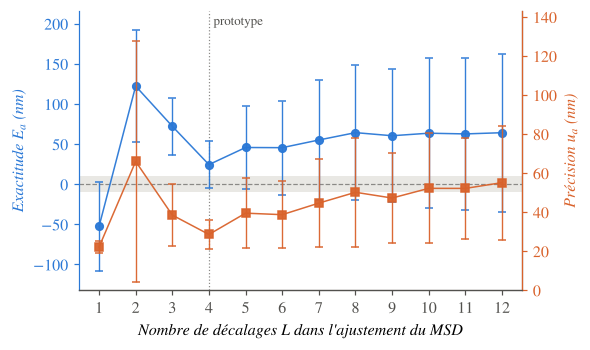

In [4]:
LS = list(range(1, 13))
res_L = [metriques([[D_piste(b["pos_msd"], d["dt"], d["pixel_eff"], L=L) for b in d["billes"]]
                    for d in donnees.values()]) for L in LS]
for L, r in zip(LS, res_L):
    print(f"L = {L:2d} : E_a = {r['E']*1e3:+6.0f} ± {r['sE']*1e3:3.0f} nm   u_a = {r['u']*1e3:4.0f} ± {r['su']*1e3:3.0f} nm"
          f"  (direct {r['u_brut']*1e3:6.0f} nm)   rayons par vidéo {np.round(r['a_v'], 3)}")
RESULTATS["L"] = dict(x=LS, res=res_L)

fig, ax = plt.subplots(figsize=(5.2, 3.3))
panneau(ax, LS, res_L, "Nombre de décalages $L$ dans l'ajustement du MSD", proto=L_PROTO, xticks=LS)
enregistrer(fig, "graphique1_lags"); plt.show()

## Graphique 2 — Fréquence d'image (exposition fixée à 90 ms)

On garde une image sur k (k = 1 à 8) dans chaque piste corrigée : Δt devient k × 92 ms, la fréquence 10,87/k
images/s, et l'exposition reste 90 ms (on ne peut pas la changer après coup). Chaque phase de décimation
(garder les images 0, k, 2k… puis 1, k+1…) est analysée séparément, puis les métriques sont moyennées sur les phases.
L reste à 4. Une bille qui garde moins de 10 positions est retirée. **La vidéo 2 est exclue de ce graphique** : ses
pistes sont trop courtes pour être décimées au-delà de k = 4 (voir la cellule).

k = 1 (10.87 img/s, Δt = 92 ms) : E_a =    -2 ±  15 nm   u_a =   20 ±   4 nm   billes 65   vidéos 3-7 [0.436 0.527 0.464 0.466 0.472]   | avec la vidéo 2 : E_a = +24 nm, u_a = 29 nm
k = 2 ( 5.44 img/s, Δt = 184 ms) : E_a =   -24 ±  13 nm   u_a =   24 ±   5 nm   billes 64   vidéos 3-7 [0.444 0.453 0.442 0.418 0.499]   | avec la vidéo 2 : E_a = +67 nm, u_a = 54 nm


k = 3 ( 3.62 img/s, Δt = 276 ms) : E_a =   -54 ±  20 nm   u_a =   29 ±   8 nm   billes 58   vidéos 3-7 [0.413 0.366 0.483 0.395 0.448]   | avec la vidéo 2 : E_a = +51 nm, u_a = 57 nm


k = 4 ( 2.72 img/s, Δt = 368 ms) : E_a =   -42 ±  35 nm   u_a =   39 ±  15 nm   billes 52   vidéos 3-7 [0.488 0.333 0.525 0.378 0.442]   | avec la vidéo 2 : E_a = +135 nm, u_a = 240 nm
k = 5 ( 2.17 img/s, Δt = 460 ms) : E_a =   -67 ±  45 nm   u_a =   37 ±   9 nm   billes 47   vidéos 3-7 [0.427 0.292 0.56  0.356 0.406]


k = 6 ( 1.81 img/s, Δt = 552 ms) : E_a =   -76 ±  43 nm   u_a =   52 ±  12 nm   billes 42   vidéos 3-7 [0.462 0.279 0.527 0.352 0.372]
k = 7 ( 1.55 img/s, Δt = 644 ms) : E_a =   -82 ±  45 nm   u_a =   50 ±  14 nm   billes 40   vidéos 3-7 [0.507 0.281 0.49  0.337 0.349]


k = 8 ( 1.36 img/s, Δt = 736 ms) : E_a =   -61 ±  69 nm   u_a =   64 ±  16 nm   billes 39   vidéos 3-7 [0.652 0.265 0.475 0.349 0.329]


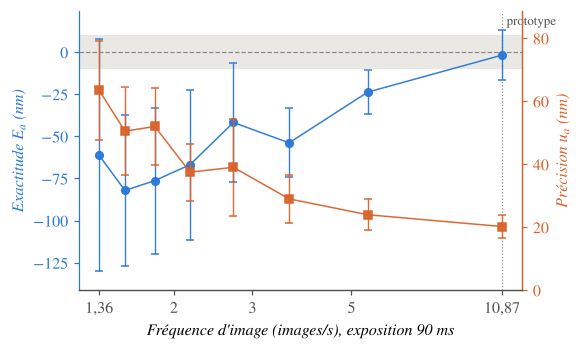

In [5]:
KS = list(range(1, 9))


def D_decime(b, k, phase, dt, pe, L=L_PROTO):
    j = np.arange(len(b["pos_msd"])) + b["f0"]          # numéro d'image (créneau) de chaque position
    return D_piste(b["pos_msd"][(j % k) == phase], k * dt, pe, L=L)


# La vidéo 2 est retirée de ce graphique : 8 de ses 9 pistes ont 26 à 43 images, donc moins de 10 positions dès k = 5;
# elle disparaîtrait en cours de balayage et ferait sauter la moyenne. Ses valeurs pour k ≤ 4 sont affichées pour info.
VIDEOS_FREQ = [v for v in VIDEOS if v != "Vidéo 2"]
res_k, fps, res_k6 = [], [], []
for k in KS:
    analyses = lambda vids: combiner([metriques([[D_decime(b, k, ph, donnees[v]["dt"], donnees[v]["pixel_eff"])
                                                   for b in donnees[v]["billes"]] for v in vids], n_boot=300)
                                      for ph in range(k)])
    moy = analyses(VIDEOS_FREQ)
    res_k.append(moy); fps.append(1 / (k * np.mean([d["dt"] for d in donnees.values()])))
    m6 = analyses(VIDEOS) if k <= 4 else None
    res_k6.append(m6)
    print(f"k = {k} ({fps[-1]:5.2f} img/s, Δt = {k*92} ms) : E_a = {moy['E']*1e3:+5.0f} ± {moy['sE']*1e3:3.0f} nm   "
          f"u_a = {moy['u']*1e3:4.0f} ± {moy['su']*1e3:3.0f} nm   billes {moy['N']:.0f}   vidéos 3-7 {np.round(moy['a_v'], 3)}"
          + (f"   | avec la vidéo 2 : E_a = {m6['E']*1e3:+.0f} nm, u_a = {m6['u']*1e3:.0f} nm" if m6 else ""))
RESULTATS["frequence"] = dict(x=fps, k=KS, res=res_k, videos=VIDEOS_FREQ, res_6videos_k_le_4=res_k6[:4])

fig, ax = plt.subplots(figsize=(5.2, 3.3))
panneau(ax, fps, res_k, "Fréquence d'image (images/s), exposition 90 ms", proto=fps[0], log=True,
        xticks=[1.36, 2, 3, 5, 10.87], xticklabels=["1,36", "2", "3", "5", "10,87"])
enregistrer(fig, "graphique2_frequence"); plt.show()

## Relocalisation dans les images dégradées (graphiques 3 et 4)

La profondeur de bits et la taille de pixel changent les images elles-mêmes. Pour chaque réglage, on dégrade
chaque image de la vidéo, puis on **relocalise chaque bille gardée et chaque bille de référence** par un ajustement
gaussien 2D (`fit_gauss_local` du code du prototype) autour de sa position connue. On retire ensuite la vibration avec
les mêmes billes de référence (`mouvement_commun`), et on calcule D avec L = 4.

* **Bits** : quantification `image // q * q` avec q = 2^(14 − b), sur les données 14 bits (0 à 16 380), de 14 à 5 bits.
* **Pixel** : somme de k × k pixels (k = 1 à 5), soit 0,374 à 1,87 µm dans le plan objet; les positions sont
  ramenées en pixels d'origine.

La détection et la liaison ne sont pas refaites (les pistes sont celles du test) : les graphiques isolent l'effet du
paramètre sur la **localisation**. Le point 14 bits / k = 1 de cette relocalisation sert de référence aux deux
graphiques (il diffère un peu du résultat officiel, localisé par le gabarit multi-billes du code extra).

In [6]:
import tifffile


def degrader(img, mode, val):
    if mode == "bits":
        q = 2 ** (14 - val)
        return (img // q * q).astype(float)
    k = val                                                        # mode == "pixel" : regroupement k × k
    H, W = img.shape[0] // k * k, img.shape[1] // k * k
    return img[:H, :W].astype(float).reshape(H // k, k, W // k, k).sum(axis=(1, 3))


def relocaliser_video(v, mode, val, frames=None):
    """Positions relocalisées (pixels d'origine) de toutes les pistes (billes gardées, puis références)."""
    fichier = CACHE / f"{v.replace(' ', '_')}_{mode}_{val}.pkl"
    if fichier.exists():
        return pickle.load(open(fichier, "rb"))
    d = donnees[v]
    if frames is None:
        frames = tifffile.imread(DOSSIER_VIDEOS / d["fichier"])
    k = val if mode == "pixel" else 1
    pistes = d["billes"] + d["refs"]
    sortie = [np.full_like(p["pos_px"], np.nan) for p in pistes]
    image_de = {int(c): i for i, c in enumerate(d["indices"])}
    for c in range(d["n_creneaux"]):
        actives = [(n, p) for n, p in enumerate(pistes)
                   if p["f0"] <= c < p["f0"] + len(p["pos_px"]) and np.isfinite(p["pos_px"][c - p["f0"], 0])]
        if not actives or c not in image_de:
            continue
        img = degrader(frames[image_de[c]], mode, val)
        fond = float(np.median(img))
        for n, p in actives:
            x0, y0 = p["pos_px"][c - p["f0"]]
            r = M.fit_gauss_local(img, (x0 + 0.5) / k - 0.5, (y0 + 0.5) / k - 0.5, fond, d["sigma_px"] / k)
            if r is not None:
                sortie[n][c - p["f0"]] = (np.array(r[:2]) + 0.5) * k - 0.5
    pickle.dump(sortie, open(fichier, "wb"))
    return sortie


def D_relocalises(v, positions, L=L_PROTO):
    """Retire la vibration (médiane des références relocalisées) puis calcule D de chaque bille gardée."""
    d = donnees[v]
    nb = len(d["billes"])
    pistes = [dict(f0=p["f0"], pos_px=pos) for p, pos in zip(d["billes"] + d["refs"], positions)]
    refs_ok = [i for i in range(nb, len(pistes)) if np.isfinite(pistes[i]["pos_px"][:, 0]).sum() >= N_MIN_PTS]
    corr = M.mouvement_commun(pistes, refs_ok, d["n_creneaux"]) if len(refs_ok) >= 2 else 0 * np.zeros((d["n_creneaux"], 2))
    D = []
    for p in pistes[:nb]:
        pos = p["pos_px"] - corr[p["f0"]:p["f0"] + len(p["pos_px"])]
        D.append(D_piste(pos, d["dt"], d["pixel_eff"], L=L))
    frac = np.mean([np.isfinite(p["pos_px"][:, 0]).sum() / max(np.isfinite(q["pos_px"][:, 0]).sum(), 1)
                    for p, q in zip(pistes[:nb], d["billes"])])
    return np.array(D), frac


BITS = [14, 13, 12, 11, 10, 9, 8, 7, 6, 5]
KPIX = [1, 2, 3, 4, 5]
t0 = time.time()
for v in VIDEOS:
    a_faire = [("bits", b) for b in BITS] + [("pixel", k) for k in KPIX if k > 1]
    if all((CACHE / f"{v.replace(' ', '_')}_{m}_{x}.pkl").exists() for m, x in a_faire):
        continue
    frames = tifffile.imread(DOSSIER_VIDEOS / donnees[v]["fichier"])
    for m, x in a_faire:
        relocaliser_video(v, m, x, frames)
        print(f"{v} {m} {x} : {time.time() - t0:.0f} s", flush=True)
    del frames
print("relocalisation prête")

relocalisation prête


## Graphique 3 — Profondeur de bits

14 bits (pas    1) : E_a =     +8 ±  31 nm   u_a =   30 ±   6 nm   positions relocalisées 99 %   billes [9, 12, 10, 10, 18, 14]


13 bits (pas    2) : E_a =     +8 ±  31 nm   u_a =   30 ±   6 nm   positions relocalisées 99 %   billes [9, 12, 10, 10, 18, 14]


12 bits (pas    4) : E_a =     +2 ±  29 nm   u_a =   30 ±   6 nm   positions relocalisées 99 %   billes [9, 12, 10, 10, 18, 14]


11 bits (pas    8) : E_a =     +4 ±  30 nm   u_a =   30 ±   6 nm   positions relocalisées 98 %   billes [9, 12, 10, 10, 18, 14]


10 bits (pas   16) : E_a =     +6 ±  28 nm   u_a =   31 ±   6 nm   positions relocalisées 98 %   billes [9, 12, 10, 10, 18, 14]


 9 bits (pas   32) : E_a =     +3 ±  30 nm   u_a =   29 ±   6 nm   positions relocalisées 98 %   billes [9, 12, 10, 10, 18, 14]


 8 bits (pas   64) : E_a =     -4 ±  31 nm   u_a =   29 ±   6 nm   positions relocalisées 97 %   billes [9, 12, 10, 10, 18, 14]


 7 bits (pas  128) : E_a =    +11 ±  22 nm   u_a =   37 ±  24 nm   positions relocalisées 90 %   billes [9, 12, 10, 9, 18, 14]


 6 bits (pas  256) : E_a =    +67 ±  81 nm   u_a =   91 ± 310 nm   positions relocalisées 83 %   billes [9, 11, 10, 9, 18, 13]


 5 bits (pas  512) : E_a =    +14 ±  52 nm   u_a =   52 ±  22 nm   positions relocalisées 72 %   billes [8, 11, 8, 9, 17, 14]


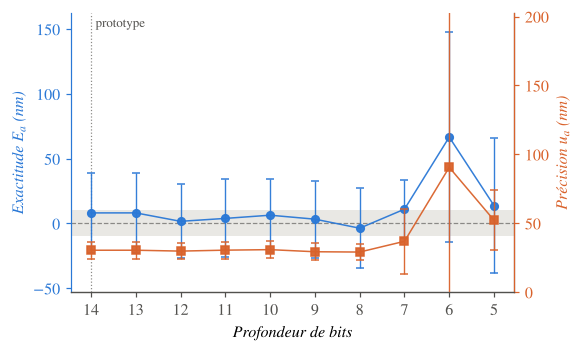

In [7]:
res_b, frac_b = [], []
for b in BITS:
    Ds, fr = zip(*[D_relocalises(v, relocaliser_video(v, "bits", b)) for v in VIDEOS])
    res_b.append(metriques(list(Ds))); frac_b.append(float(np.mean(fr)))
    r = res_b[-1]
    print(f"{b:2d} bits (pas {2**(14-b):4d}) : E_a = {r['E']*1e3:+6.0f} ± {r['sE']*1e3:3.0f} nm   "
          f"u_a = {r['u']*1e3:4.0f} ± {r['su']*1e3:3.0f} nm   positions relocalisées {100*frac_b[-1]:.0f} %   "
          f"billes {r['N']}")
RESULTATS["bits"] = dict(x=BITS, res=res_b, frac_localisee=frac_b)

fig, ax = plt.subplots(figsize=(5.2, 3.3))
panneau(ax, BITS, res_b, "Profondeur de bits", proto=14, xticks=BITS)
ax.invert_xaxis()
enregistrer(fig, "graphique3_bits"); plt.show()

## Graphique 4 — Taille de pixel (dans le plan objet)

k = 1 (0.374 µm) : E_a =     +8 ±  31 nm   u_a =   30 ±   6 nm   positions relocalisées 99 %   billes [9, 12, 10, 10, 18, 14]
k = 2 (0.749 µm) : E_a =    +27 ±  42 nm   u_a =   34 ±   8 nm   positions relocalisées 99 %   billes [9, 12, 10, 10, 18, 15]


k = 3 (1.123 µm) : E_a =    +18 ±  72 nm   u_a =   56 ±  42 nm   positions relocalisées 97 %   billes [9, 12, 10, 10, 18, 14]
k = 4 (1.497 µm) : E_a =    +83 ±  70 nm   u_a =   55 ±  32 nm   positions relocalisées 96 %   billes [9, 12, 10, 10, 18, 14]


k = 5 (1.871 µm) : E_a =    +38 ±  39 nm   u_a =   45 ±  25 nm   positions relocalisées 92 %   billes [9, 12, 10, 9, 18, 13]


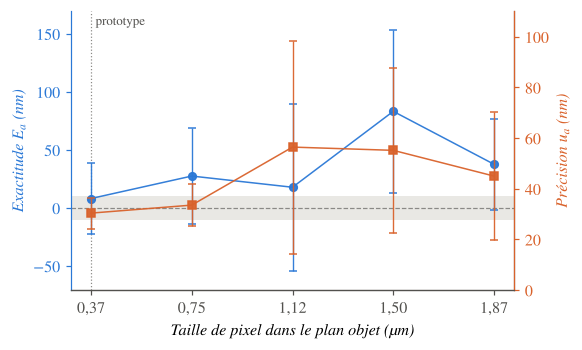

In [8]:
res_p, frac_p = [], []
pix_um = [k * donnees[VIDEOS[0]]["pixel_eff"] * 1e6 for k in KPIX]
for k in KPIX:
    Ds, fr = zip(*[D_relocalises(v, relocaliser_video(v, "bits", 14) if k == 1 else relocaliser_video(v, "pixel", k))
                   for v in VIDEOS])
    res_p.append(metriques(list(Ds))); frac_p.append(float(np.mean(fr)))
    r = res_p[-1]
    print(f"k = {k} ({pix_um[k-1]:.3f} µm) : E_a = {r['E']*1e3:+6.0f} ± {r['sE']*1e3:3.0f} nm   "
          f"u_a = {r['u']*1e3:4.0f} ± {r['su']*1e3:3.0f} nm   positions relocalisées {100*frac_p[-1]:.0f} %   "
          f"billes {r['N']}")
RESULTATS["pixel"] = dict(x=pix_um, k=KPIX, res=res_p, frac_localisee=frac_p)

fig, ax = plt.subplots(figsize=(5.2, 3.3))
panneau(ax, pix_um, res_p, "Taille de pixel dans le plan objet (µm)", proto=pix_um[0], xticks=pix_um,
        xticklabels=[f"{p:.2f}".replace(".", ",") for p in pix_um])
enregistrer(fig, "graphique4_pixel"); plt.show()

## Graphique 5 — Quantité de données

**a) Nombre d'images.** On ne garde que n images consécutives de chaque vidéo (n = 20 à 111, la longueur de la
plus courte vidéo), comme si l'enregistrement s'était arrêté après n images. Pour ne pas dépendre du début de la
vidéo, la fenêtre est placée à 5 positions régulièrement espacées dans chaque vidéo et les métriques sont moyennées.

**b) Nombre de billes.** On tire au hasard N billes (avec remise) parmi les 74 billes gardées des 6 vidéos, 2000
fois. Rayon estimé : a = kT/(6πη·moyenne des D); exactitude : moyenne des tirages − 0,475 µm, avec en barre
l'écart type des tirages (la dispersion réelle de l'estimation); précision : std(a_i)/√N (par propagation depuis
les D_i, comme ailleurs), médiane des tirages. Les deux barres doivent se ressembler si u_a est une bonne estimation.

n =  20 images (  1.8 s) : E_a =    -10 ±  24 nm   u_a =   48 ±   9 nm   billes 44
n =  25 images (  2.3 s) : E_a =     -3 ±  13 nm   u_a =   42 ±   7 nm   billes 47


n =  30 images (  2.8 s) : E_a =     -1 ±  12 nm   u_a =   36 ±  10 nm   billes 49


n =  40 images (  3.7 s) : E_a =    +14 ±  24 nm   u_a =   37 ±   7 nm   billes 50
n =  50 images (  4.6 s) : E_a =    +10 ±  21 nm   u_a =   32 ±   6 nm   billes 52


n =  60 images (  5.5 s) : E_a =    +22 ±  22 nm   u_a =   33 ±   7 nm   billes 57
n =  70 images (  6.4 s) : E_a =    +18 ±  21 nm   u_a =   33 ±   7 nm   billes 59


n =  80 images (  7.4 s) : E_a =    +18 ±  26 nm   u_a =   30 ±   6 nm   billes 61
n =  90 images (  8.3 s) : E_a =    +13 ±  19 nm   u_a =   26 ±   4 nm   billes 64


n = 100 images (  9.2 s) : E_a =    +16 ±  19 nm   u_a =   30 ±   4 nm   billes 67
n = 111 images ( 10.2 s) : E_a =    +13 ±  18 nm   u_a =   28 ±   5 nm   billes 69
N =  3 billes : E_a =    +38 nm, dispersion des tirages  139 nm, u_a =  112 ±  99 nm
N =  5 billes : E_a =    +26 nm, dispersion des tirages   96 nm, u_a =   85 ±  52 nm
N =  8 billes : E_a =    +21 nm, dispersion des tirages   70 nm, u_a =   66 ±  29 nm
N = 10 billes : E_a =    +18 nm, dispersion des tirages   63 nm, u_a =   58 ±  23 nm
N = 15 billes : E_a =    +16 nm, dispersion des tirages   49 nm, u_a =   48 ±  14 nm
N = 20 billes : E_a =    +13 nm, dispersion des tirages   42 nm, u_a =   42 ±  11 nm
N = 30 billes : E_a =    +11 nm, dispersion des tirages   35 nm, u_a =   33 ±   7 nm
N = 40 billes : E_a =    +12 nm, dispersion des tirages   30 nm, u_a =   29 ±   5 nm
N = 50 billes : E_a =    +11 nm, dispersion des tirages   27 nm, u_a =   26 ±   4 nm
N = 60 billes : E_a =    +12 nm, dispersion des tirages   24 nm, u_a 

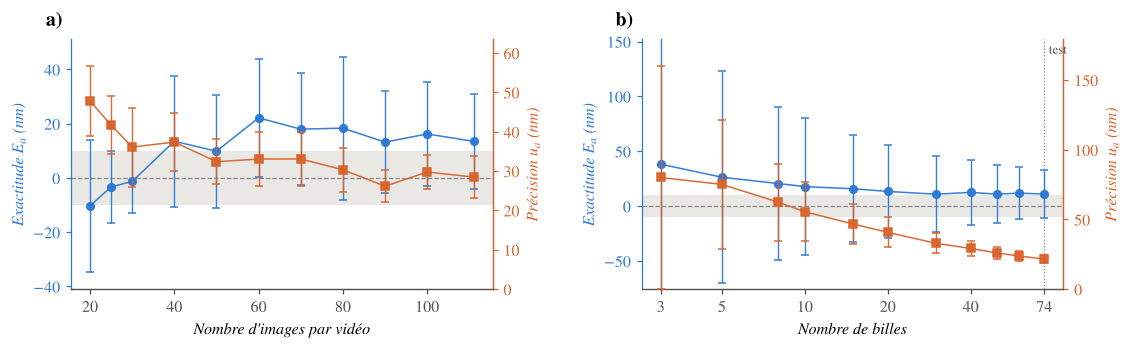

In [9]:
N_IMG = [20, 25, 30, 40, 50, 60, 70, 80, 90, 100, 111]
N_FEN = 5


def D_fenetre(b, debut, n, dt, pe):
    c = np.arange(len(b["pos_msd"])) + b["f0"]
    return D_piste(b["pos_msd"][(c >= debut) & (c < debut + n)], dt, pe)


res_n = []
for n in N_IMG:
    par_fen = []
    for r_ in range(N_FEN):
        Dv = []
        for d in donnees.values():
            debut = int(round(r_ / (N_FEN - 1) * (d["n_creneaux"] - n)))
            Dv.append([D_fenetre(b, debut, n, d["dt"], d["pixel_eff"]) for b in d["billes"]])
        par_fen.append(metriques(Dv, n_boot=300))
    moy = combiner(par_fen)
    res_n.append(moy)
    print(f"n = {n:3d} images ({n*0.092:5.1f} s) : E_a = {moy['E']*1e3:+6.0f} ± {moy['sE']*1e3:3.0f} nm   "
          f"u_a = {moy['u']*1e3:4.0f} ± {moy['su']*1e3:3.0f} nm   billes {moy['N']:.0f}")
RESULTATS["n_images"] = dict(x=N_IMG, res=res_n)

D_tous = np.concatenate([[D_piste(b["pos_msd"], d["dt"], d["pixel_eff"]) for b in d["billes"]]
                         for d in donnees.values()])
D_tous = D_tous[np.isfinite(D_tous)]
N_BILLES = [3, 5, 8, 10, 15, 20, 30, 40, 50, 60, 74]
rng = np.random.default_rng(GRAINE)
res_N = []
for N in N_BILLES:
    tir = rng.choice(D_tous, size=(2000, N))
    a = rayon_um(tir.mean(axis=1))
    u = a * np.std(tir, axis=1, ddof=1) / np.sqrt(N) / tir.mean(axis=1)          # même propagation que u_video
    res_N.append(dict(E=a.mean() - A_VRAI_UM, sE=a.std(), u=float(np.median(u)),
                      su=float(np.diff(np.percentile(u, [16, 84]))[0] / 2), N=N))
    print(f"N = {N:2d} billes : E_a = {res_N[-1]['E']*1e3:+6.0f} nm, dispersion des tirages {a.std()*1e3:4.0f} nm, "
          f"u_a = {u.mean()*1e3:4.0f} ± {u.std()*1e3:3.0f} nm")
RESULTATS["n_billes"] = dict(x=N_BILLES, res=res_N)

fig, axs = plt.subplots(1, 2, figsize=(10.4, 3.3))
panneau(axs[0], N_IMG, res_n, "Nombre d'images par vidéo", lettre="a)", proto=None)
panneau(axs[1], N_BILLES, res_N, "Nombre de billes", lettre="b)", proto=74, note_proto="test", log=True,
        xticks=[3, 5, 10, 20, 40, 74], xticklabels=["3", "5", "10", "20", "40", "74"])
fig.tight_layout(w_pad=2.5)
enregistrer(fig, "graphique5_quantite_donnees"); plt.show()

## Figure d'ensemble (format de la brochure)

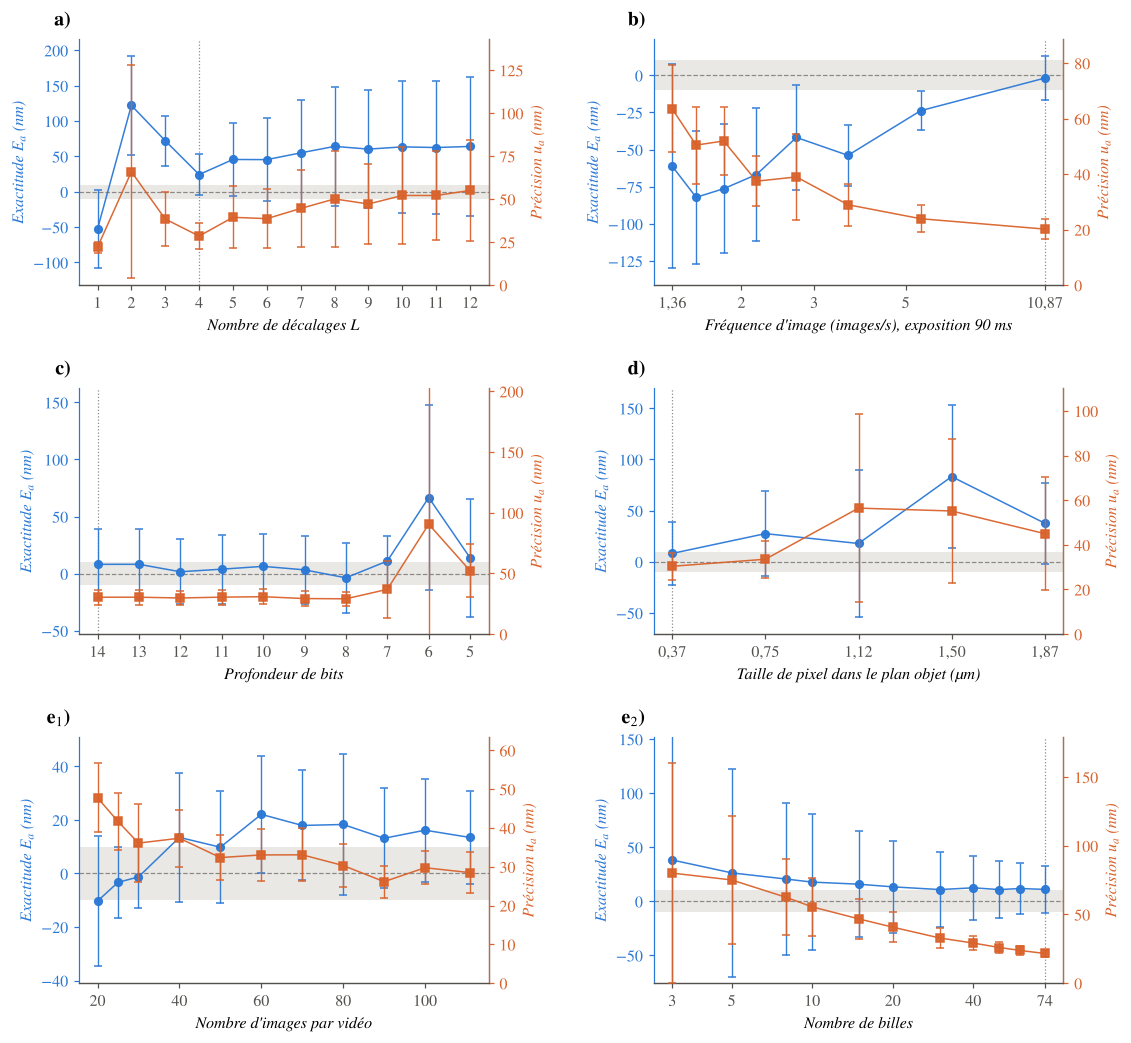

In [10]:
fig, axs = plt.subplots(3, 2, figsize=(10.4, 9.6))
panneau(axs[0, 0], LS, res_L, "Nombre de décalages $L$", lettre="a)", proto=L_PROTO, xticks=LS, note_proto=None)
panneau(axs[0, 1], fps, res_k, "Fréquence d'image (images/s), exposition 90 ms", lettre="b)", proto=fps[0], log=True,
        xticks=[1.36, 2, 3, 5, 10.87], xticklabels=["1,36", "2", "3", "5", "10,87"], note_proto=None)
panneau(axs[1, 0], BITS, res_b, "Profondeur de bits", lettre="c)", proto=14, xticks=BITS, note_proto=None)
axs[1, 0].invert_xaxis()
panneau(axs[1, 1], pix_um, res_p, "Taille de pixel dans le plan objet (µm)", lettre="d)", proto=pix_um[0],
        xticks=pix_um, xticklabels=[f"{p:.2f}".replace(".", ",") for p in pix_um], note_proto=None)
panneau(axs[2, 0], N_IMG, res_n, "Nombre d'images par vidéo", lettre="e$_1$)")
panneau(axs[2, 1], N_BILLES, res_N, "Nombre de billes", lettre="e$_2$)", proto=74, log=True,
        xticks=[3, 5, 10, 20, 40, 74], xticklabels=["3", "5", "10", "20", "40", "74"], note_proto=None)
fig.tight_layout(h_pad=1.6, w_pad=2.5)
enregistrer(fig, "graphiques_1a5_ensemble"); plt.show()

## Export des données en CSV

Trois fichiers dans `fig_performance/` (séparateur virgule, point décimal, UTF-8) :

* `performance_resume.csv` : une ligne par point tracé (E_a, u_a et leurs barres, en nm), pour les 6 graphiques;
* `performance_par_video.csv` : une ligne par vidéo et par analyse (D moyen, rayon a_v, u_v, nombre de billes);
* `performance_par_bille.csv` : une ligne par bille et par analyse (D_i et a_i), c.-à-d. les valeurs individuelles.

Une « analyse » est une phase de décimation (graphique 2) ou une position de fenêtre (graphique 5a); les autres
graphiques n'en ont qu'une. Le graphique 5b (tirages de billes) n'a pas de valeurs par bille propres : il tire dans
les 74 D_i du réglage L = 4 (graphique 1, L = 4).

In [11]:
import csv

par_bille, par_video = [], []


def noter(graphique, parametre, x, analyse, videos, D_par_video, extra=None):
    """Consigne les D_i de chaque bille et le résumé de chaque vidéo pour une analyse."""
    for v, D in zip(videos, D_par_video):
        d = donnees[v]
        D = np.asarray(D, float)
        for b, Di in zip(d["billes"], D):
            par_bille.append(dict(graphique=graphique, parametre=parametre, valeur=x, analyse=analyse, video=v,
                                  fichier=d["fichier"], piste=b["piste"],
                                  n_positions=int(np.isfinite(b["pos_msd"][:, 0]).sum()),
                                  D_um2_s=Di * 1e12 if np.isfinite(Di) else None,
                                  a_um=float(rayon_um(Di)) if np.isfinite(Di) and Di > 0 else None,
                                  retenue=bool(np.isfinite(Di)), **(extra or {})))
        ok = D[np.isfinite(D)]
        valide = len(ok) >= 2 and ok.mean() > 0
        par_video.append(dict(graphique=graphique, parametre=parametre, valeur=x, analyse=analyse, video=v,
                              N_billes=len(ok), D_moy_um2_s=ok.mean() * 1e12 if len(ok) else None,
                              std_D_um2_s=ok.std(ddof=1) * 1e12 if len(ok) > 1 else None,
                              a_v_um=float(rayon_um(ok.mean())) if valide else None,
                              u_v_nm=float(u_video(ok)) * 1e3 if valide else None,
                              a_officiel_um=d["a_officiel"] * 1e6, **(extra or {})))


for L in LS:
    noter("1", "L", L, 0, VIDEOS, [[D_piste(b["pos_msd"], d["dt"], d["pixel_eff"], L=L) for b in d["billes"]]
                                   for d in donnees.values()])
for k, f in zip(KS, fps):
    for ph in range(k):
        noter("2", "frequence_img_s", round(f, 4), ph, VIDEOS_FREQ,
              [[D_decime(b, k, ph, donnees[v]["dt"], donnees[v]["pixel_eff"]) for b in donnees[v]["billes"]]
               for v in VIDEOS_FREQ], extra=dict(k_decimation=k))
for b_ in BITS:
    Ds = [D_relocalises(v, relocaliser_video(v, "bits", b_))[0] for v in VIDEOS]
    noter("3", "bits", b_, 0, VIDEOS, Ds)
for k, px in zip(KPIX, pix_um):
    Ds = [D_relocalises(v, relocaliser_video(v, "bits", 14) if k == 1 else relocaliser_video(v, "pixel", k))[0]
          for v in VIDEOS]
    noter("4", "pixel_um", round(px, 4), 0, VIDEOS, Ds, extra=dict(k_binning=k))
for n in N_IMG:
    for r_ in range(N_FEN):
        Dv, debuts = [], []
        for d in donnees.values():
            debut = int(round(r_ / (N_FEN - 1) * (d["n_creneaux"] - n)))
            Dv.append([D_fenetre(b, debut, n, d["dt"], d["pixel_eff"]) for b in d["billes"]])
        noter("5a", "n_images", n, r_, VIDEOS, Dv)

resume = []
for g, cle, par in [("1", "L", "L"), ("2", "frequence", "frequence_img_s"), ("3", "bits", "bits"),
                    ("4", "pixel", "pixel_um"), ("5a", "n_images", "n_images"), ("5b", "n_billes", "n_billes")]:
    R = RESULTATS[cle]
    for i, (x, r) in enumerate(zip(R["x"], R["res"])):
        ligne = dict(graphique=g, parametre=par, valeur=round(float(x), 4),
                     E_a_nm=r["E"] * 1e3, barre_E_a_nm=r["sE"] * 1e3, u_a_nm=r["u"] * 1e3, barre_u_a_nm=r["su"] * 1e3,
                     a_estime_um=r["E"] + A_VRAI_UM,
                     N_billes=float(np.sum(r["N"])) if np.ndim(r.get("N", np.nan)) else r.get("N"),
                     n_videos=len(r["a_v"]) if "a_v" in r else None,
                     fraction_positions_relocalisees=R.get("frac_localisee", [None] * 99)[i],
                     u_a_direct_nm=r["u_brut"] * 1e3 if "u_brut" in r else None)
        resume.append(ligne)


def ecrire(nom, lignes):
    cles = list(dict.fromkeys(k for l in lignes for k in l))
    with open(FIG / nom, "w", newline="", encoding="utf-8-sig") as f:
        w = csv.DictWriter(f, fieldnames=cles)
        w.writeheader()
        for l in lignes:
            w.writerow({k: (f"{v:.6g}" if isinstance(v, (float, np.floating)) else v) for k, v in l.items()})
    print(f"{nom} : {len(lignes)} lignes")


ecrire("performance_resume.csv", resume)
ecrire("performance_par_video.csv", par_video)
ecrire("performance_par_bille.csv", par_bille)

performance_resume.csv : 57 lignes
performance_par_video.csv : 672 lignes
performance_par_bille.csv : 8408 lignes


## Annexe — Pertes d'images pendant l'acquisition

Chaque acquisition enregistre l'horodatage de chaque image (`timestamps_ns` du .json). Un écart de plus de 1,5 fois
la durée d'image prévue signale des images perdues; leur nombre est l'écart arrondi divisé par la durée d'image, moins 1.

In [12]:
acq = []
for f in sorted(DOSSIER_JSON.glob("*.json")):
    j = json.load(open(f))
    if "timestamps_ns" not in j or "_part_" in f.name or len(j["timestamps_ns"]) < 5:
        continue
    t = (np.array(j["timestamps_ns"], float) - j["timestamps_ns"][0]) / 1e9
    T0 = j.get("duree_image_consigne_us", 92000) / 1e6
    ecarts = np.diff(t)
    perdues = np.where(ecarts > 1.5 * T0, np.round(ecarts / T0) - 1, 0)
    premier = int(np.argmax(perdues > 0)) + 1 if perdues.any() else len(t)
    nom = f.stem.split("_2026")[0]
    acq.append(dict(nom=nom, fichier=f.name, option=j.get("option", "?"), g=j.get("grossissement"), t=t, T0=T0,
                    perdues=perdues, n=len(t), n_perdues=int(perdues.sum()), duree=t[-1],
                    frac=perdues.sum() / (len(t) + perdues.sum()), premier=premier,
                    t_premier=t[premier - 1] if perdues.any() else np.nan,
                    largeur=j.get("largeur_px"), hauteur=j.get("hauteur_px")))
for a in acq:
    print(f"{a['fichier']:48s} option {a['option']} {a['largeur']}×{a['hauteur']} : {a['n']:4d} images reçues, "
          f"{a['n_perdues']:4d} perdues ({100*a['frac']:4.1f} %), durée {a['duree']:5.1f} s, "
          f"1re perte après {a['premier']} images ({a['t_premier']:.1f} s)")
RESULTATS["pertes"] = [{k: (v if not isinstance(v, np.ndarray) else None) for k, v in a.items() if k not in ("t", "perdues")}
                       for a in acq]

100nano1_2026-11-09_12h57m59_C_40X.json          option C 1014×760 :  143 images reçues,   19 perdues (11.7 %), durée  14.8 s, 1re perte après 88 images (8.0 s)
acq_2026-11-02_13h21m47_B_20X.json               option B 2028×1520 :   50 images reçues,   13 perdues (20.6 %), durée   6.2 s, 1re perte après 30 images (2.9 s)
acq_2026-11-02_13h59m13_C_20X.json               option C 1014×760 :   67 images reçues,    0 perdues ( 0.0 %), durée   6.1 s, 1re perte après 67 images (nan s)
acq_2026-11-02_14h01m03_A_20X.json               option A 2028×1520 :   74 images reçues,   17 perdues (18.7 %), durée   9.0 s, 1re perte après 6 images (0.5 s)
acq_2026-11-02_14h03m01_D_20X.json               option D 4056×3040 :   29 images reçues,    0 perdues ( 0.0 %), durée   2.8 s, 1re perte après 29 images (nan s)
inconnu1_2026-11-09_13h04m18_C_40X.json          option C 1014×760 :  268 images reçues,  302 perdues (53.0 %), durée  52.4 s, 1re perte après 86 images (7.8 s)
inconnu2_20x_2026-11-09_13h27m18

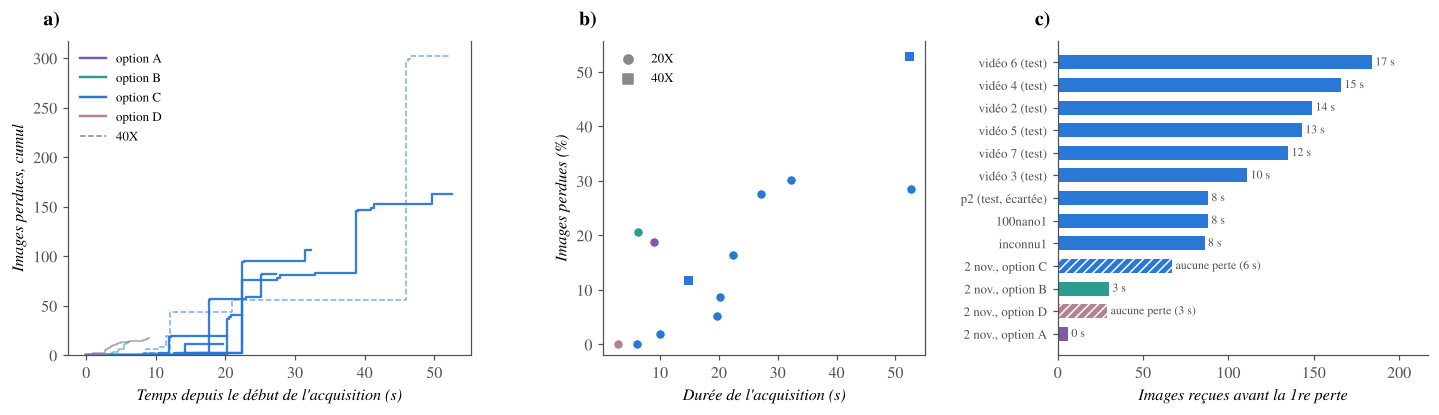

In [13]:
C_OPT = {"A": "#7d5ba6", "B": "#2a9d8f", "C": BLEU, "D": "#b5838d"}


def etiquette(a):
    if a["nom"].startswith("acq"):
        return f"2 nov., option {a['option']}"
    return {"inconnu2_20x": "vidéo 2 (test)", "inconnu2_p2": "p2 (test, écartée)"}.get(
        a["nom"], a["nom"].replace("inconnu2_p", "vidéo ").replace("_20x", "") + (" (test)" if a["nom"].startswith("inconnu2_p") else ""))


def lettre(ax, t):
    ax.text(-0.02, 1.035, t, transform=ax.transAxes, fontsize=13, fontweight="bold", va="bottom", ha="right")


fig, axs = plt.subplots(1, 3, figsize=(13.2, 3.9), gridspec_kw=dict(width_ratios=[1.25, 1, 1.15]))
ax = axs[0]
for a in sorted(acq, key=lambda a: a["option"] != "C"):
    cumul = np.concatenate([[0], np.cumsum(a["perdues"])])
    test = a["nom"].startswith("inconnu2") and a["nom"] != "inconnu2_p2"
    ax.step(a["t"], cumul, where="post", color=C_OPT.get(a["option"], GRIS), lw=1.5 if test else 1.0,
            alpha=0.95 if test else 0.6, ls="-" if a["g"] == 20 else "--")
ax.set_xlabel("Temps depuis le début de l'acquisition (s)", style="italic")
ax.set_ylabel("Images perdues, cumul", style="italic")
ax.set_ylim(0, None)
lettre(ax, "a)")
for o, c in C_OPT.items():
    if any(a["option"] == o for a in acq):
        ax.plot([], [], color=c, lw=1.6, label=f"option {o}")
ax.plot([], [], color=GRIS, ls="--", lw=1, label="40X")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")

ax = axs[1]
for a in acq:
    ax.scatter(a["duree"], 100 * a["frac"], s=38, color=C_OPT.get(a["option"], GRIS), edgecolor="white", lw=0.6,
               marker="o" if a["g"] == 20 else "s", zorder=3)
ax.set_xlabel("Durée de l'acquisition (s)", style="italic")
ax.set_ylabel("Images perdues (%)", style="italic")
ax.scatter([], [], color=GRIS, marker="o", label="20X"); ax.scatter([], [], color=GRIS, marker="s", label="40X")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
ax.set_ylim(-2, None)
lettre(ax, "b)")

ax = axs[2]
ordre = sorted(acq, key=lambda a: a["premier"])
y = np.arange(len(ordre))
ax.barh(y, [a["premier"] for a in ordre], color=[C_OPT.get(a["option"], GRIS) for a in ordre], height=0.62,
        hatch=[None if np.isfinite(a["t_premier"]) else "////" for a in ordre], edgecolor="white", lw=0)
ax.set_yticks(y); ax.set_yticklabels([etiquette(a) for a in ordre], fontsize=8.5)
ax.set_xlabel("Images reçues avant la 1re perte", style="italic")
for yy, a in zip(y, ordre):
    txt = f"{a['t_premier']:.0f} s" if np.isfinite(a["t_premier"]) else f"aucune perte ({a['duree']:.0f} s)"
    ax.text(a["premier"] + 2, yy, txt, va="center", fontsize=7.8, color="#52514e")
ax.set_xlim(0, max(a["premier"] for a in acq) * 1.18)
ax.spines["right"].set_visible(False)
lettre(ax, "c)")
fig.tight_layout(w_pad=2.2)
enregistrer(fig, "annexe_pertes_images"); plt.show()

## Export des résultats numériques

In [14]:
def nettoyer(o):
    if isinstance(o, dict):
        return {k: nettoyer(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [nettoyer(v) for v in o]
    if isinstance(o, np.ndarray):
        return nettoyer(o.tolist())
    if isinstance(o, (np.floating, float)):
        return None if not np.isfinite(o) else round(float(o), 6)
    if isinstance(o, np.integer):
        return int(o)
    return o


json.dump(nettoyer(RESULTATS), open(FIG / "resultats_performance.json", "w"), indent=1, ensure_ascii=False)
print("écrit :", sorted(p.name for p in FIG.iterdir()))

écrit : ['annexe_pertes_images.pdf', 'annexe_pertes_images.png', 'graphique1_lags.pdf', 'graphique1_lags.png', 'graphique2_frequence.pdf', 'graphique2_frequence.png', 'graphique3_bits.pdf', 'graphique3_bits.png', 'graphique4_pixel.pdf', 'graphique4_pixel.png', 'graphique5_quantite_donnees.pdf', 'graphique5_quantite_donnees.png', 'graphiques_1a5_ensemble.pdf', 'graphiques_1a5_ensemble.png', 'performance_par_bille.csv', 'performance_par_video.csv', 'performance_resume.csv', 'resultats_performance.json']
